## Лабораторная работа №2

ФИО: Топакова Полина Васильевна

Номер студенческого билета: 230470

Вариант: 0
- Датасет: Fashion-MNIST.
- Архитектура: 784 → 128 → 10.
- Функция активации: ReLU.
- Начальный learning rate: 0.10

Подготовка окружения

In [57]:
import copy
import random
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

SEED = 42
DEVICE = torch.device("cpu")
BATCH_SIZE = 64
EPOCHS = 30
START_LR = 0.10

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

set_seed()

загрузка датасета и создание DataLoader

In [58]:
transform = transforms.ToTensor()

full_train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

split_generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=split_generator
)

class_names = full_train_dataset.classes

def make_train_loader(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0
    )

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

train_loader = make_train_loader()

print("Размер обучающей выборки:", len(train_dataset))
print("Размер валидационной выборки:", len(val_dataset))
print("Размер тестовой выборки:", len(test_dataset))
print("Количество классов:", len(class_names))
print("Классы:", class_names)

Размер обучающей выборки: 48000
Размер валидационной выборки: 12000
Размер тестовой выборки: 10000
Количество классов: 10
Классы: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


просмотр нескольких изображений

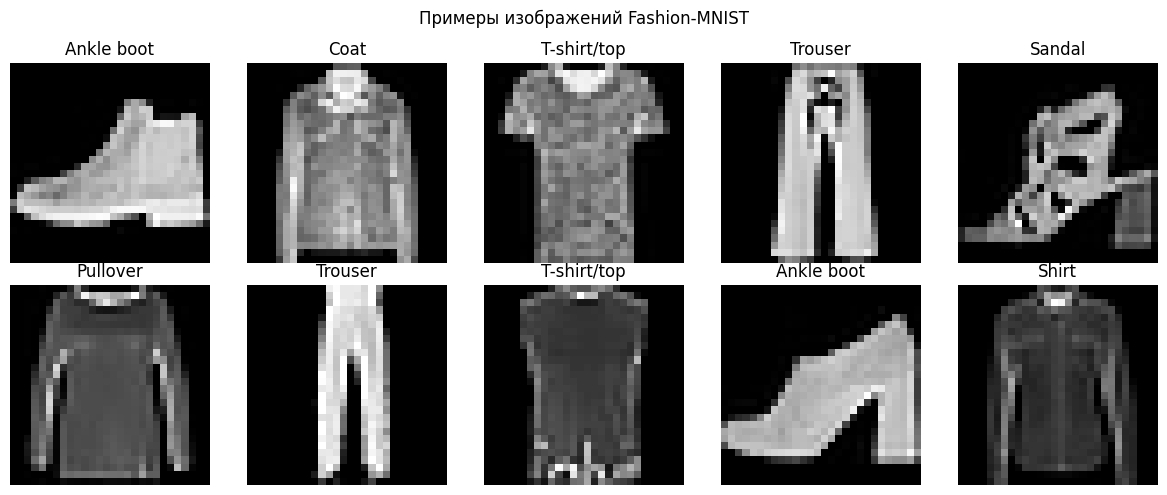

In [59]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.suptitle("Примеры изображений Fashion-MNIST")
plt.tight_layout()
plt.show()

Для классификации используется многослойный перцептрон (MLP). Входной слой получает 784 значения пикселей, скрытый слой содержит 128 нейронов и функцию активации ReLU, выходной слой содержит 10 нейронов — по одному на каждый класс одежды

In [60]:
class FashionMLP(nn.Module):
    def __init__(self, dropout_p=0.0):
        super().__init__()

        layers = [
            nn.Linear(784, 128),
            nn.ReLU()
        ]

        if dropout_p > 0:
            layers.append(nn.Dropout(dropout_p))

        layers.append(nn.Linear(128, 10))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.network(x)


criterion = nn.CrossEntropyLoss()

set_seed()
model = FashionMLP().to(DEVICE)

print(model)
print("Количество параметров:", sum(p.numel() for p in model.parameters()))

FashionMLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)
Количество параметров: 101770


функции оценки и ручного обучения

In [61]:
@torch.no_grad()
def evaluate_loss_accuracy(model, loader):
    model.eval()

    total_loss = 0.0
    all_targets = []
    all_predictions = []

    for x, y in loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)

        predictions = logits.argmax(dim=1)
        all_targets.extend(y.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    average_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_targets, all_predictions)
    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "targets": np.array(all_targets),
        "predictions": np.array(all_predictions)
    }


def train_epoch_manual(model, loader, lr, weight_decay=0.0):
    model.train()
    total_loss = 0.0

    for x, y in loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        model.zero_grad(set_to_none=True)

        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()

        with torch.no_grad():
            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter -= lr * (parameter.grad + weight_decay * parameter)

        total_loss += loss.item() * x.size(0)

    return total_loss / len(loader.dataset)


def train_manual(
    model,
    epochs=EPOCHS,
    lr=START_LR,
    weight_decay=0.0,
    patience=None,
    seed=SEED
):
    loader = make_train_loader(seed)
    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_macro_f1": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss = train_epoch_manual(model, loader, lr, weight_decay)
        val_metrics = evaluate_loss_accuracy(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Эпоха {epoch + 1:02d}/{epochs} | "
            f"train loss: {train_loss:.4f} | "
            f"val loss: {val_metrics['loss']:.4f} | "
            f"val accuracy: {val_metrics['accuracy']:.4f}"
        )

        if patience is not None and epochs_without_improvement >= patience:
            print(f"Ранняя остановка на эпохе {epoch + 1}")
            break

    return history, best_state, best_epoch

Код — обучение вручную

In [62]:
set_seed()
manual_model = FashionMLP().to(DEVICE)

initial_state = copy.deepcopy(manual_model.state_dict())

manual_history, manual_best_state, manual_best_epoch = train_manual(
    manual_model,
    epochs=EPOCHS,
    lr=START_LR,
    seed=SEED
)

manual_model.load_state_dict(manual_best_state)

manual_result = evaluate_loss_accuracy(manual_model, val_loader)

print("\nРезультат ручного обучения:")
print("Лучшая эпоха:", manual_best_epoch)
print(f"Validation loss: {manual_result['loss']:.4f}")
print(f"Validation Accuracy: {manual_result['accuracy']:.4f}")
print(f"Validation Macro-F1: {manual_result['macro_f1']:.4f}")

Эпоха 01/30 | train loss: 0.6646 | val loss: 0.5214 | val accuracy: 0.8232
Эпоха 02/30 | train loss: 0.4576 | val loss: 0.4322 | val accuracy: 0.8471
Эпоха 03/30 | train loss: 0.4126 | val loss: 0.4359 | val accuracy: 0.8399
Эпоха 04/30 | train loss: 0.3844 | val loss: 0.3882 | val accuracy: 0.8620
Эпоха 05/30 | train loss: 0.3640 | val loss: 0.3785 | val accuracy: 0.8645
Эпоха 06/30 | train loss: 0.3488 | val loss: 0.3663 | val accuracy: 0.8711
Эпоха 07/30 | train loss: 0.3339 | val loss: 0.3440 | val accuracy: 0.8778
Эпоха 08/30 | train loss: 0.3236 | val loss: 0.3627 | val accuracy: 0.8686
Эпоха 09/30 | train loss: 0.3131 | val loss: 0.3327 | val accuracy: 0.8797
Эпоха 10/30 | train loss: 0.3038 | val loss: 0.3460 | val accuracy: 0.8744
Эпоха 11/30 | train loss: 0.2950 | val loss: 0.3324 | val accuracy: 0.8802
Эпоха 12/30 | train loss: 0.2883 | val loss: 0.4055 | val accuracy: 0.8489
Эпоха 13/30 | train loss: 0.2805 | val loss: 0.3247 | val accuracy: 0.8826
Эпоха 14/30 | train loss:

Теперь обучается такая же сеть с использованием стандартного оптимизатора torch.optim.SGD

In [63]:
def train_epoch_optimizer(model, loader, optimizer):
    model.train()
    total_loss = 0.0

    for x, y in loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)

    return total_loss / len(loader.dataset)


def train_with_sgd(
    model,
    epochs=EPOCHS,
    lr=START_LR,
    weight_decay=0.0,
    patience=None,
    seed=SEED
):
    loader = make_train_loader(seed)
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_macro_f1": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss = train_epoch_optimizer(model, loader, optimizer)
        val_metrics = evaluate_loss_accuracy(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Эпоха {epoch + 1:02d}/{epochs} | "
            f"train loss: {train_loss:.4f} | "
            f"val loss: {val_metrics['loss']:.4f} | "
            f"val accuracy: {val_metrics['accuracy']:.4f}"
        )

        if patience is not None and epochs_without_improvement >= patience:
            print(f"Ранняя остановка на эпохе {epoch + 1}")
            break

    return history, best_state, best_epoch


sgd_model = FashionMLP().to(DEVICE)
sgd_model.load_state_dict(initial_state)

sgd_history, sgd_best_state, sgd_best_epoch = train_with_sgd(
    sgd_model,
    epochs=EPOCHS,
    lr=START_LR,
    seed=SEED
)

sgd_model.load_state_dict(sgd_best_state)
sgd_result = evaluate_loss_accuracy(sgd_model, val_loader)

comparison_manual_sgd = pd.DataFrame([
    {
        "Метод": "Ручное обновление",
        "Лучшая эпоха": manual_best_epoch,
        "Validation loss": manual_result["loss"],
        "Accuracy": manual_result["accuracy"],
        "Macro-F1": manual_result["macro_f1"]
    },
    {
        "Метод": "torch.optim.SGD",
        "Лучшая эпоха": sgd_best_epoch,
        "Validation loss": sgd_result["loss"],
        "Accuracy": sgd_result["accuracy"],
        "Macro-F1": sgd_result["macro_f1"]
    }
])

comparison_manual_sgd

Эпоха 01/30 | train loss: 0.6647 | val loss: 0.5215 | val accuracy: 0.8235
Эпоха 02/30 | train loss: 0.4577 | val loss: 0.4318 | val accuracy: 0.8474
Эпоха 03/30 | train loss: 0.4126 | val loss: 0.4360 | val accuracy: 0.8393
Эпоха 04/30 | train loss: 0.3840 | val loss: 0.3877 | val accuracy: 0.8614
Эпоха 05/30 | train loss: 0.3638 | val loss: 0.3737 | val accuracy: 0.8661
Эпоха 06/30 | train loss: 0.3489 | val loss: 0.3639 | val accuracy: 0.8721
Эпоха 07/30 | train loss: 0.3340 | val loss: 0.3451 | val accuracy: 0.8765
Эпоха 08/30 | train loss: 0.3233 | val loss: 0.3579 | val accuracy: 0.8709
Эпоха 09/30 | train loss: 0.3126 | val loss: 0.3312 | val accuracy: 0.8818
Эпоха 10/30 | train loss: 0.3035 | val loss: 0.3459 | val accuracy: 0.8743
Эпоха 11/30 | train loss: 0.2956 | val loss: 0.3342 | val accuracy: 0.8798
Эпоха 12/30 | train loss: 0.2891 | val loss: 0.3785 | val accuracy: 0.8589
Эпоха 13/30 | train loss: 0.2810 | val loss: 0.3229 | val accuracy: 0.8833
Эпоха 14/30 | train loss:

,Метод,Лучшая эпоха,Validation loss,Accuracy,Macro-F1
0,Ручное обновление,20,0.307359,0.891250,0.891669
1,torch.optim.SGD,27,0.307851,0.889417,0.889773


графики ручного обучения и SGD

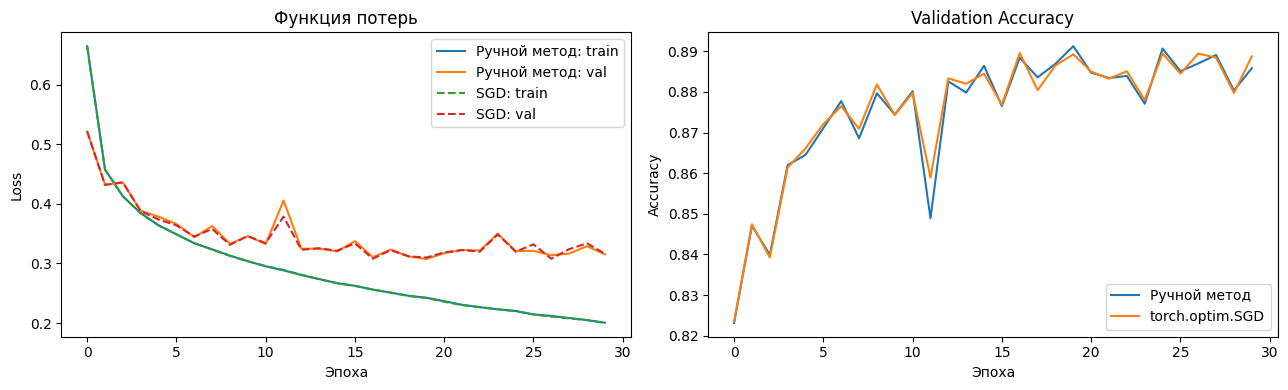

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    manual_history["train_loss"],
    label="Ручной метод: train"
)
axes[0].plot(
    manual_history["val_loss"],
    label="Ручной метод: val"
)
axes[0].plot(
    sgd_history["train_loss"],
    linestyle="--",
    label="SGD: train"
)
axes[0].plot(
    sgd_history["val_loss"],
    linestyle="--",
    label="SGD: val"
)
axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    manual_history["val_accuracy"],
    label="Ручной метод"
)
axes[1].plot(
    sgd_history["val_accuracy"],
    label="torch.optim.SGD"
)
axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

подбор learning rate

In [65]:
learning_rates = [0.001, 0.01, 0.10, 0.50]
LR_EPOCHS = 5

lr_histories = {}
lr_rows = []

for lr in learning_rates:
    print(f"\n{'=' * 15} Learning rate = {lr} {'=' * 15}")

    set_seed()
    lr_model = FashionMLP().to(DEVICE)

    history, best_state, best_epoch = train_with_sgd(
        lr_model,
        epochs=LR_EPOCHS,
        lr=lr,
        seed=SEED
    )

    lr_model.load_state_dict(best_state)
    result = evaluate_loss_accuracy(lr_model, val_loader)

    lr_histories[lr] = history

    best_index = int(np.argmin(history["val_loss"]))

    lr_rows.append({
        "Learning rate": lr,
        "Лучшая эпоха": best_epoch,
        "Лучший val loss": min(history["val_loss"]),
        "Val Accuracy": history["val_accuracy"][best_index],
        "Val Macro-F1": history["val_macro_f1"][best_index]
    })

lr_results = pd.DataFrame(lr_rows)
lr_results.sort_values("Лучший val loss")


=============== Learning rate = 0.001 ===============
Эпоха 01/5 | train loss: 2.1175 | val loss: 1.9412 | val accuracy: 0.5857
Эпоха 02/5 | train loss: 1.7575 | val loss: 1.5818 | val accuracy: 0.6364
Эпоха 03/5 | train loss: 1.4398 | val loss: 1.3197 | val accuracy: 0.6478
Эпоха 04/5 | train loss: 1.2266 | val loss: 1.1531 | val accuracy: 0.6517
Эпоха 05/5 | train loss: 1.0901 | val loss: 1.0447 | val accuracy: 0.6619

=============== Learning rate = 0.01 ===============
Эпоха 01/5 | train loss: 1.2170 | val loss: 0.8183 | val accuracy: 0.6993
Эпоха 02/5 | train loss: 0.7200 | val loss: 0.6649 | val accuracy: 0.7758
Эпоха 03/5 | train loss: 0.6145 | val loss: 0.5950 | val accuracy: 0.7993
Эпоха 04/5 | train loss: 0.5584 | val loss: 0.5513 | val accuracy: 0.8158
Эпоха 05/5 | train loss: 0.5243 | val loss: 0.5268 | val accuracy: 0.8265

=============== Learning rate = 0.1 ===============
Эпоха 01/5 | train loss: 0.6647 | val loss: 0.5215 | val accuracy: 0.8235
Эпоха 02/5 | train loss:

,Learning rate,Лучшая эпоха,Лучший val loss,Val Accuracy,Val Macro-F1
2,0.100,5,0.373736,0.866083,0.862885
3,0.500,4,0.406939,0.856833,0.853715
1,0.010,5,0.526756,0.826500,0.822235
0,0.001,5,1.044700,0.661917,0.612110


графики для разных learning rate

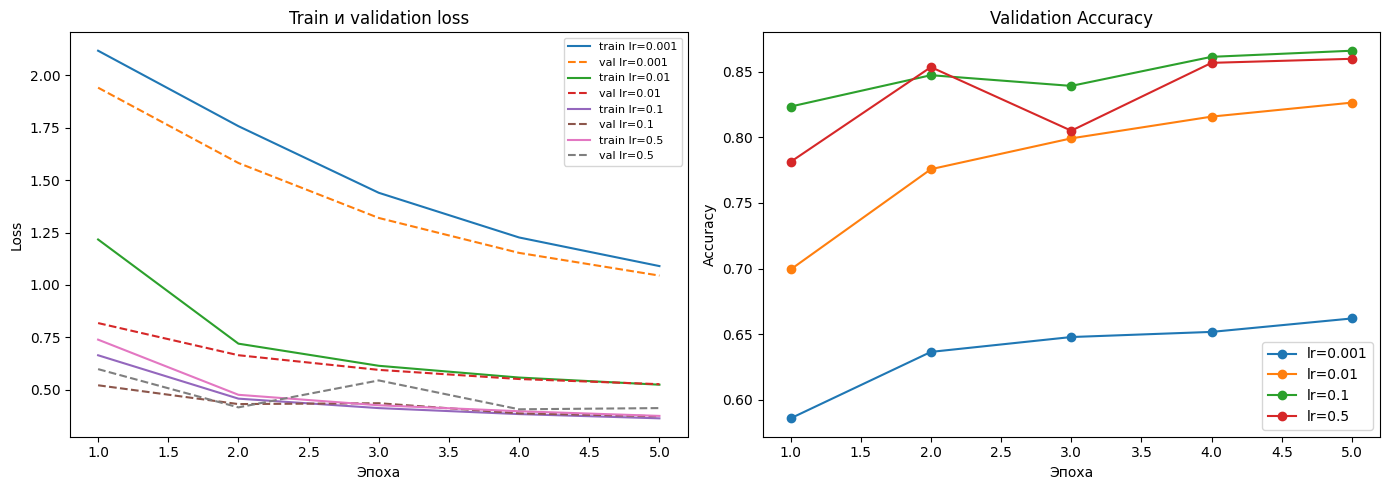

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for lr, history in lr_histories.items():
    epochs = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(
        epochs,
        history["train_loss"],
        label=f"train lr={lr}"
    )
    axes[0].plot(
        epochs,
        history["val_loss"],
        linestyle="--",
        label=f"val lr={lr}"
    )

    axes[1].plot(
        epochs,
        history["val_accuracy"],
        marker="o",
        label=f"lr={lr}"
    )

axes[0].set_title("Train и validation loss")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

сравнение регуляризации
Проверяется влияние трёх подходов:
- Baseline — исходная сеть без дополнительной регуляризации.
- Dropout — случайное отключение части нейронов во время обучения.
- Weight decay — штраф за большие значения весов, добавляемый оптимизатором.


Для сравнения используется одна и та же базовая архитектура (784→128→10, ReLU). Конфигурации отличаются только методом регуляризации: baseline — без неё, dropout — слой Dropout(0.2) в скрытом слое, weight decay — L2-штраф 1e-4 в оптимизаторе. Число эпох и lr фиксированы

In [67]:
regularization_configs = [
    {
        "Название": "Baseline",
        "dropout": 0.0,
        "weight_decay": 0.0
    },
    {
        "Название": "Dropout 0.2",
        "dropout": 0.2,
        "weight_decay": 0.0
    },
    {
        "Название": "Weight decay 0.0001",
        "dropout": 0.0,
        "weight_decay": 0.0001
    }
]

regularization_histories = {}
regularization_rows = []

for config in regularization_configs:
    print(f"\nЭксперимент: {config['Название']}")

    set_seed()
    reg_model = FashionMLP(
        dropout_p=config["dropout"]
    ).to(DEVICE)

    history, best_state, best_epoch = train_with_sgd(
        reg_model,
        epochs=EPOCHS,
        lr=START_LR,
        weight_decay=config["weight_decay"],
        seed=SEED
    )

    reg_model.load_state_dict(best_state)
    result = evaluate_loss_accuracy(reg_model, val_loader)

    regularization_histories[config["Название"]] = history

    best_index = int(np.argmin(history["val_loss"]))

    regularization_rows.append({
        "Метод": config["Название"],
        "Лучшая эпоха": best_epoch,
        "Лучший val loss": history["val_loss"][best_index],
        "Val Accuracy": history["val_accuracy"][best_index],
        "Val Macro-F1": history["val_macro_f1"][best_index]
    })

regularization_results = pd.DataFrame(regularization_rows)
regularization_results.sort_values("Лучший val loss")


Эксперимент: Baseline
Эпоха 01/30 | train loss: 0.6647 | val loss: 0.5215 | val accuracy: 0.8235
Эпоха 02/30 | train loss: 0.4577 | val loss: 0.4318 | val accuracy: 0.8474
Эпоха 03/30 | train loss: 0.4126 | val loss: 0.4360 | val accuracy: 0.8393
Эпоха 04/30 | train loss: 0.3840 | val loss: 0.3877 | val accuracy: 0.8614
Эпоха 05/30 | train loss: 0.3638 | val loss: 0.3737 | val accuracy: 0.8661
Эпоха 06/30 | train loss: 0.3489 | val loss: 0.3639 | val accuracy: 0.8721
Эпоха 07/30 | train loss: 0.3340 | val loss: 0.3451 | val accuracy: 0.8765
Эпоха 08/30 | train loss: 0.3233 | val loss: 0.3579 | val accuracy: 0.8709
Эпоха 09/30 | train loss: 0.3126 | val loss: 0.3312 | val accuracy: 0.8818
Эпоха 10/30 | train loss: 0.3035 | val loss: 0.3459 | val accuracy: 0.8743
Эпоха 11/30 | train loss: 0.2956 | val loss: 0.3342 | val accuracy: 0.8798
Эпоха 12/30 | train loss: 0.2891 | val loss: 0.3785 | val accuracy: 0.8589
Эпоха 13/30 | train loss: 0.2810 | val loss: 0.3229 | val accuracy: 0.8833
Эп

,Метод,Лучшая эпоха,Лучший val loss,Val Accuracy,Val Macro-F1
0,Baseline,27,0.307851,0.889417,0.889773
2,Weight decay 0.0001,20,0.310203,0.888250,0.889058
1,Dropout 0.2,30,0.311392,0.887000,0.886779


На выбранной архитектуре и 30 эпохах переобучение не наступает, поэтому регуляризация не дает прироста. Это ожидаемо для простой модели на Fashion-MNIST.

графики регуляризации

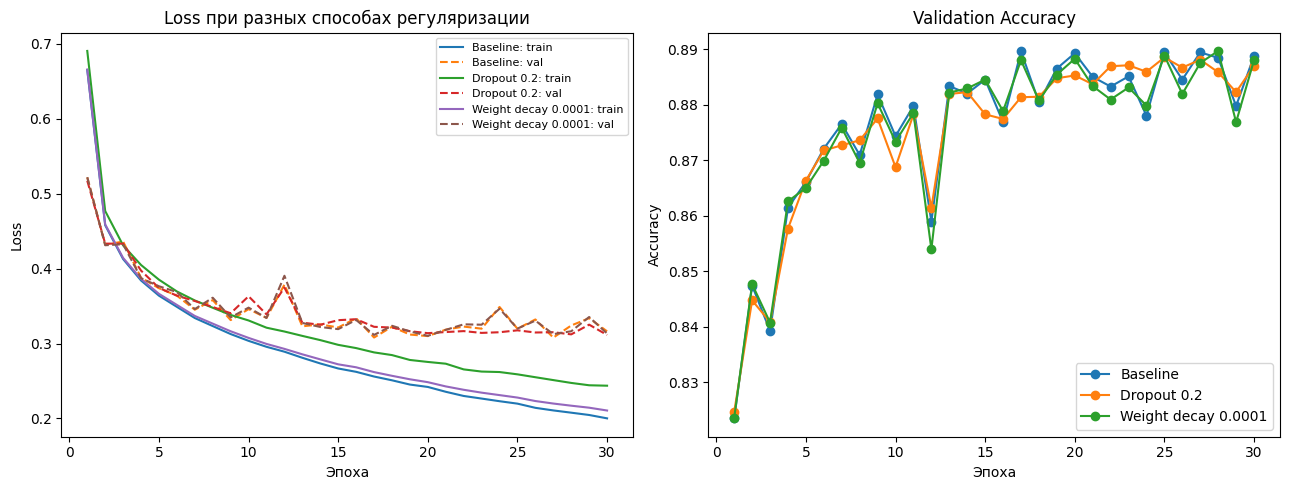

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, history in regularization_histories.items():
    epochs = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(
        epochs,
        history["train_loss"],
        label=f"{name}: train"
    )
    axes[0].plot(
        epochs,
        history["val_loss"],
        linestyle="--",
        label=f"{name}: val"
    )
    axes[1].plot(
        epochs,
        history["val_accuracy"],
        marker="o",
        label=name
    )

axes[0].set_title("Loss при разных способах регуляризации")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

Ранняя остановка (early stopping) прекращает обучение, если качество на валидационной выборке перестаёт улучшаться в течение заданного числа эпох. Это позволяет избежать лишнего обучения и может уменьшить переобучение.

В эксперименте используется patience = 2. Результат сравнивается с обучением в течение фиксированного числа эпох. Для корректной оценки после ранней остановки восстанавливаются параметры модели с лучшим validation loss.

In [69]:
PATIENCE = 5
set_seed()
early_model = FashionMLP().to(DEVICE)

early_history, early_best_state, early_best_epoch = train_with_sgd(
    early_model,
    epochs=EPOCHS,
    lr=START_LR,
    patience=PATIENCE,
    seed=SEED
)

early_model.load_state_dict(early_best_state)
early_result = evaluate_loss_accuracy(early_model, val_loader)

set_seed()
fixed_model = FashionMLP().to(DEVICE)

fixed_history, fixed_best_state, fixed_best_epoch = train_with_sgd(
    fixed_model,
    epochs=EPOCHS,
    lr=START_LR,
    patience=None,
    seed=SEED
)

fixed_model.load_state_dict(fixed_best_state)
fixed_result = evaluate_loss_accuracy(fixed_model, val_loader)

early_stopping_results = pd.DataFrame([
    {
        "Метод": "Early stopping",
        "Эпоха лучшей модели": early_best_epoch,
        "Фактически выполнено эпох": len(early_history["train_loss"]),
        "Лучший val loss": early_result["loss"],
        "Val Accuracy": early_result["accuracy"],
        "Val Macro-F1": early_result["macro_f1"]
    },
    {
        "Метод": "Фиксированное обучение",
        "Эпоха лучшей модели": fixed_best_epoch,
        "Фактически выполнено эпох": len(fixed_history["train_loss"]),
        "Лучший val loss": fixed_result["loss"],
        "Val Accuracy": fixed_result["accuracy"],
        "Val Macro-F1": fixed_result["macro_f1"]
    }
])

early_stopping_results

Эпоха 01/30 | train loss: 0.6647 | val loss: 0.5215 | val accuracy: 0.8235
Эпоха 02/30 | train loss: 0.4577 | val loss: 0.4318 | val accuracy: 0.8474
Эпоха 03/30 | train loss: 0.4126 | val loss: 0.4360 | val accuracy: 0.8393
Эпоха 04/30 | train loss: 0.3840 | val loss: 0.3877 | val accuracy: 0.8614
Эпоха 05/30 | train loss: 0.3638 | val loss: 0.3737 | val accuracy: 0.8661
Эпоха 06/30 | train loss: 0.3489 | val loss: 0.3639 | val accuracy: 0.8721
Эпоха 07/30 | train loss: 0.3340 | val loss: 0.3451 | val accuracy: 0.8765
Эпоха 08/30 | train loss: 0.3233 | val loss: 0.3579 | val accuracy: 0.8709
Эпоха 09/30 | train loss: 0.3126 | val loss: 0.3312 | val accuracy: 0.8818
Эпоха 10/30 | train loss: 0.3035 | val loss: 0.3459 | val accuracy: 0.8743
Эпоха 11/30 | train loss: 0.2956 | val loss: 0.3342 | val accuracy: 0.8798
Эпоха 12/30 | train loss: 0.2891 | val loss: 0.3785 | val accuracy: 0.8589
Эпоха 13/30 | train loss: 0.2810 | val loss: 0.3229 | val accuracy: 0.8833
Эпоха 14/30 | train loss:

,Метод,Эпоха лучшей модели,Фактически выполнено эпох,Лучший val loss,Val Accuracy,Val Macro-F1
0,Early stopping,17,22,0.307977,0.889583,0.889815
1,Фиксированное обучение,27,30,0.307851,0.889417,0.889773


early stopping сработал на 22-й эпохе, вернув веса 17-й. Это позволило избежать лишних вычислений, но при этом качество модели (val loss 0.3079) практически совпало с финальным результатом при 30 эпохах (0.3078)

Для итоговой оценки берём baseline-модель, обученную через torch.optim.SGD

In [70]:
final_val_result = evaluate_loss_accuracy(sgd_model, val_loader)

print(f"Validation Accuracy: {final_val_result['accuracy']:.4f}")
print(f"Validation Macro-F1: {final_val_result['macro_f1']:.4f}")
print(f"Validation Loss: {final_val_result['loss']:.4f}")

print("\nОтчёт по классам:")
print(
    classification_report(
        final_val_result["targets"],
        final_val_result["predictions"],
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

Validation Accuracy: 0.8894
Validation Macro-F1: 0.8898
Validation Loss: 0.3079

Отчёт по классам:
              precision    recall  f1-score   support

 T-shirt/top       0.88      0.80      0.83      1268
     Trouser       0.99      0.98      0.99      1248
    Pullover       0.84      0.82      0.83      1175
       Dress       0.86      0.92      0.89      1148
        Coat       0.82      0.83      0.83      1193
      Sandal       0.97      0.94      0.95      1203
       Shirt       0.70      0.74      0.72      1212
     Sneaker       0.90      0.97      0.94      1134
         Bag       0.96      0.96      0.96      1195
  Ankle boot       0.98      0.93      0.95      1224

    accuracy                           0.89     12000
   macro avg       0.89      0.89      0.89     12000
weighted avg       0.89      0.89      0.89     12000



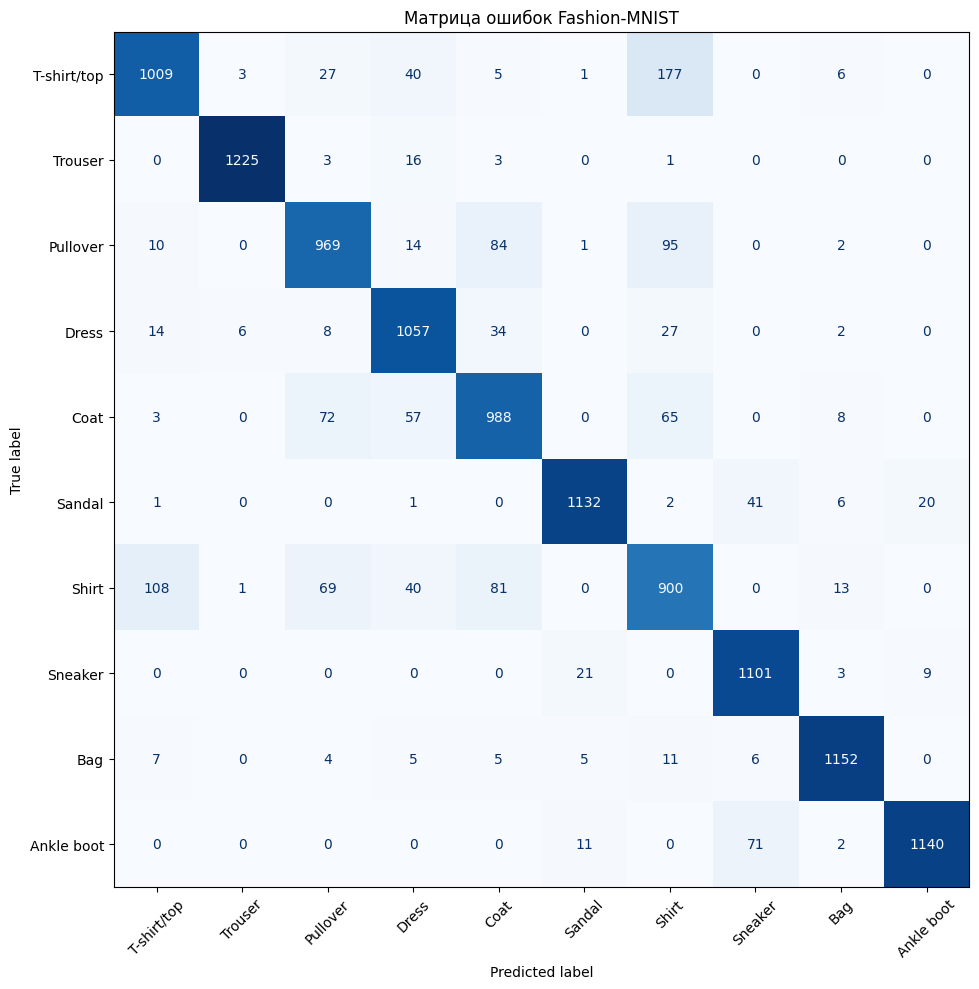

In [71]:
cm = confusion_matrix(
    final_val_result["targets"],
    final_val_result["predictions"],
    labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Матрица ошибок Fashion-MNIST")
plt.tight_layout()
plt.show()

In [72]:
test_result = evaluate_loss_accuracy(sgd_model, test_loader)

print("Итоговая оценка на тестовой выборке")
print(f"Test loss: {test_result['loss']:.4f}")
print(f"Test Accuracy: {test_result['accuracy']:.4f}")
print(f"Test Macro-F1: {test_result['macro_f1']:.4f}")

Итоговая оценка на тестовой выборке
Test loss: 0.3330
Test Accuracy: 0.8824
Test Macro-F1: 0.8829


In [73]:
print("1. Ручное обучение и стандартный SGD")
display(comparison_manual_sgd)

print("2. Подбор learning rate")
display(lr_results.sort_values("Лучший val loss"))

print("3. Сравнение регуляризации")
display(regularization_results.sort_values("Лучший val loss"))

print("4. Ранняя остановка")
display(early_stopping_results)

1. Ручное обучение и стандартный SGD


,Метод,Лучшая эпоха,Validation loss,Accuracy,Macro-F1
0,Ручное обновление,20,0.307359,0.891250,0.891669
1,torch.optim.SGD,27,0.307851,0.889417,0.889773


2. Подбор learning rate


,Learning rate,Лучшая эпоха,Лучший val loss,Val Accuracy,Val Macro-F1
2,0.100,5,0.373736,0.866083,0.862885
3,0.500,4,0.406939,0.856833,0.853715
1,0.010,5,0.526756,0.826500,0.822235
0,0.001,5,1.044700,0.661917,0.612110


3. Сравнение регуляризации


,Метод,Лучшая эпоха,Лучший val loss,Val Accuracy,Val Macro-F1
0,Baseline,27,0.307851,0.889417,0.889773
2,Weight decay 0.0001,20,0.310203,0.888250,0.889058
1,Dropout 0.2,30,0.311392,0.887000,0.886779


4. Ранняя остановка


,Метод,Эпоха лучшей модели,Фактически выполнено эпох,Лучший val loss,Val Accuracy,Val Macro-F1
0,Early stopping,17,22,0.307977,0.889583,0.889815
1,Фиксированное обучение,27,30,0.307851,0.889417,0.889773
